# Proyecto Integrador — Avance II: Modelos de clasificación

**Proyecto:** Homicidios intencionales en Ecuador  
**Dataset:** `dataset_homicidios_final.csv` del Avance I  
**Unidad:** distrito, fecha y franja horaria  
**Objetivo:** `categoria_incidencia` (`baja`, `media`, `alta`)

Se integran los tres algoritmos solicitados: **regresión logística, árbol de decisión y SVM (LinearSVC)**. El árbol y el SVM toman como referencia los cuadernos `DecisionTreeModel.ipynb` y `SVMModel.ipynb` del equipo. Las comparaciones se realizan con las mismas variables, muestra de entrenamiento y período de prueba.

## 1. Dataset y carga

El archivo debe estar en `MyDrive/ModelLOA/Datos_Procesados/dataset_homicidios_final.csv`. No es necesario reconstruir el dataset desde los Excel originales.

In [ ]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

try:
    from google.colab import drive
    drive.mount('/content/drive')
    RUTA_DATOS = Path('/content/drive/MyDrive/ModelLOA/Datos_Procesados/dataset_homicidios_final.csv')
except ImportError:
    RUTA_DATOS = Path('dataset_homicidios_final.csv')
    if not RUTA_DATOS.exists():
        RUTA_DATOS = Path('/mnt/data/dataset_homicidios_final.csv')

if not RUTA_DATOS.exists():
    raise FileNotFoundError(f'No se encontró el archivo: {RUTA_DATOS}')
print('Ruta:', RUTA_DATOS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ruta: /content/drive/MyDrive/ModelLOA/Datos_Procesados/dataset_homicidios_final.csv


In [ ]:
COLUMNAS = [
    'codigo_provincia', 'codigo_distrito', 'fecha', 'mes',
    'dia_semana_num', 'dia_semana', 'franja_horaria',
    'es_feriado', 'nombre_feriado', 'total_homicidios',
    'categoria_incidencia'
]

df = pd.read_csv(
    RUTA_DATOS, encoding='utf-8-sig',
    dtype={'codigo_provincia':'string', 'codigo_distrito':'string'},
    low_memory=False
)
faltantes = sorted(set(COLUMNAS) - set(df.columns))
if faltantes:
    raise ValueError(f'Faltan columnas: {faltantes}')
df = df[COLUMNAS].copy()
df['fecha'] = pd.to_datetime(df['fecha'], dayfirst=True, errors='coerce')
df['categoria_incidencia'] = df['categoria_incidencia'].astype('string').str.strip().str.lower()
df['anio'] = df['fecha'].dt.year

print(f'Registros: {len(df):,} | Provincias: {df.codigo_provincia.nunique()} | Distritos: {df.codigo_distrito.nunique()}')
print('Período:', df.fecha.min(), 'a', df.fecha.max())
display(df.head())

Registros: 2,590,560 | Provincias: 24 | Distritos: 140
Período: 2014-01-01 00:00:00 a 2026-08-31 00:00:00


,codigo_provincia,codigo_distrito,fecha,mes,dia_semana_num,dia_semana,franja_horaria,es_feriado,nombre_feriado,total_homicidios,categoria_incidencia,anio
0,01,01D01,2014-01-01,1,2,Miercoles,madrugada,1,Año Nuevo,1,media,2014
1,01,01D01,2014-01-01,1,2,Miercoles,manana,1,Año Nuevo,0,baja,2014
2,01,01D01,2014-01-01,1,2,Miercoles,noche,1,Año Nuevo,0,baja,2014
3,01,01D01,2014-01-01,1,2,Miercoles,tarde,1,Año Nuevo,0,baja,2014
4,01,01D01,2014-01-02,1,3,Jueves,madrugada,0,NO_FERIADO,0,baja,2014


## 2. Validación y definición de clases

Se conserva la definición del Avance I: **baja = 0 víctimas**, **media = 1 víctima** y **alta = 2 o más víctimas**. Estos niveles reflejan ocurrencia registrada en cada unidad de análisis; **no constituyen categorías oficiales de riesgo**.

,Registros,Porcentaje
categoria_incidencia,,
baja,2554560,98.61
media,29994,1.158
alta,6006,0.232


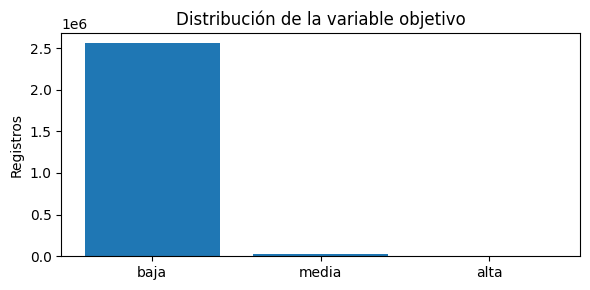

In [ ]:
CLASES = ['baja','media','alta']
CLAVES = ['codigo_provincia','codigo_distrito','fecha','franja_horaria']

if df[COLUMNAS].isna().any().any():
    display(df[COLUMNAS].isna().sum().to_frame('Valores nulos'))
    raise ValueError('Se encontraron valores nulos.')
if df.duplicated(CLAVES).any():
    raise ValueError('Existen unidades de análisis duplicadas.')
if not df.categoria_incidencia.isin(CLASES).all():
    raise ValueError('Categorías inesperadas.')

esperadas = np.select(
    [df.total_homicidios.eq(0), df.total_homicidios.eq(1)],
    ['baja','media'], default='alta'
)
if not np.array_equal(esperadas, df.categoria_incidencia.to_numpy()):
    raise ValueError('Las categorías no coinciden con total_homicidios.')
if len(df) == 1_048_575:
    warnings.warn('La cantidad de filas coincide con el límite de Excel: verificar que el CSV no esté recortado.')

frecuencias = df.categoria_incidencia.value_counts().reindex(CLASES,fill_value=0)
display(pd.DataFrame({
    'Registros': frecuencias,
    'Porcentaje': (100 * frecuencias / len(df)).round(3)
}))
fig, ax = plt.subplots(figsize=(6,3))
ax.bar(frecuencias.index, frecuencias.values)
ax.set(title='Distribución de la variable objetivo', ylabel='Registros')
plt.tight_layout()
plt.show()

## 3. Preparación y división temporal

Se usa la fecha de corte correspondiente al **percentil 80 de los registros**, criterio del árbol de decisión original. La prueba incluye únicamente fechas posteriores al período de entrenamiento.

Por el tamaño del dataset, el SVM del equipo empleaba una muestra **estratificada de 300.000 registros de entrenamiento**. Para comparar algoritmos bajo las mismas condiciones, **esa misma muestra se utiliza en los tres modelos**. Cambia `TAM_MUESTRA_ENTRENAMIENTO = None` para entrenar con todo el período histórico, si la capacidad de Colab lo permite.

`total_homicidios` no se usa como predictor porque determina directamente la etiqueta y ocasionaría fuga de información.

In [ ]:
CATEGORICAS = ['codigo_provincia','codigo_distrito','franja_horaria']
NUMERICAS = ['es_feriado','anio','mes','dia_semana_num']
PREDICTORAS = CATEGORICAS + NUMERICAS
TAM_MUESTRA_ENTRENAMIENTO = 300_000
SEMILLA = 42

X = df[PREDICTORAS]
y = df['categoria_incidencia']
fecha_corte = df.fecha.quantile(0.80)
mascara_train = df.fecha < fecha_corte
mascara_test = ~mascara_train

X_train_total, y_train_total = X.loc[mascara_train], y.loc[mascara_train]
X_test, y_test = X.loc[mascara_test], y.loc[mascara_test]

if X_train_total.empty or X_test.empty:
    raise ValueError('La división temporal generó un conjunto vacío.')
if set(CLASES) - set(y_train_total.unique()):
    raise ValueError('Faltan categorías en entrenamiento.')

if TAM_MUESTRA_ENTRENAMIENTO is not None and TAM_MUESTRA_ENTRENAMIENTO < len(y_train_total):
    indices_entrenamiento, _ = train_test_split(
        np.arange(len(y_train_total)), train_size=TAM_MUESTRA_ENTRENAMIENTO,
        stratify=y_train_total, random_state=SEMILLA
    )
    X_train = X_train_total.iloc[indices_entrenamiento]
    y_train = y_train_total.iloc[indices_entrenamiento]
else:
    X_train, y_train = X_train_total, y_train_total

print('Fecha de corte:', fecha_corte.date())
print(f'Entrenamiento temporal disponible: {len(X_train_total):,}')
print(f'Muestra común de entrenamiento: {len(X_train):,}')
print(f'Prueba temporal completa: {len(X_test):,}')
display(pd.DataFrame({
    'Entrenamiento': y_train.value_counts().reindex(CLASES,fill_value=0),
    'Prueba': y_test.value_counts().reindex(CLASES,fill_value=0)
}))

Fecha de corte: 2024-02-18
Entrenamiento temporal disponible: 2,072,000
Muestra común de entrenamiento: 300,000
Prueba temporal completa: 518,560


,Entrenamiento,Prueba
categoria_incidencia,,
baja,297095,502620
media,2529,12530
alta,376,3410


La codificación de categorías y el escalado numérico se ajustan **exclusivamente con entrenamiento** y se aplican sin cambios a la prueba. Los tres algoritmos usan estas mismas matrices.

In [ ]:
preprocesador = ColumnTransformer(
    transformers=[
        ('categoricas', OneHotEncoder(handle_unknown='ignore', dtype=np.float32), CATEGORICAS),
        ('numericas', StandardScaler(), NUMERICAS)
    ],
    sparse_threshold=1.0
)
X_train_p = preprocesador.fit_transform(X_train)
X_test_p = preprocesador.transform(X_test)
print('Entrenamiento:', X_train_p.shape, '| Prueba:', X_test_p.shape)

Entrenamiento: (300000, 172) | Prueba: (518560, 172)


## 4. Desarrollo de modelos

Se aplica `class_weight='balanced'` debido al desbalance. Los parámetros del árbol provienen del notebook del equipo; el SVM utiliza `LinearSVC` con **C = 1**, como en su notebook, y `dual=False` para un entrenamiento más eficiente con más filas que variables.

### 4.1. Regresión logística

In [ ]:
modelo_logistico = LogisticRegression(
    solver='lbfgs', max_iter=300, tol=1e-3,
    class_weight='balanced', random_state=SEMILLA
)
modelo_logistico.fit(X_train_p, y_train)
pred_logistica = modelo_logistico.predict(X_test_p)
print('Regresión logística entrenada.')

Regresión logística entrenada.


### 4.2. Árbol de decisión

In [ ]:
modelo_arbol = DecisionTreeClassifier(
    criterion='gini', max_depth=15,
    min_samples_split=10, min_samples_leaf=5,
    class_weight='balanced', random_state=SEMILLA
)
modelo_arbol.fit(X_train_p, y_train)
pred_arbol = modelo_arbol.predict(X_test_p)
print('Árbol de decisión entrenado.')

Árbol de decisión entrenado.


### 4.3. SVM — LinearSVC

In [ ]:
modelo_svm = LinearSVC(
    C=1.0, dual=False, class_weight='balanced',
    random_state=SEMILLA, max_iter=5000, tol=1e-3
)
modelo_svm.fit(X_train_p, y_train)
pred_svm = modelo_svm.predict(X_test_p)
print('SVM entrenado.')

SVM entrenado.


## 5. Evaluación: métricas y matrices de confusión

Se reportan **Accuracy, Precision, Recall y F1-Score**, el informe por clase y las matrices en conteos y proporciones. La comparación principal utiliza el **promedio macro**, porque la clase `baja` es dominante. También se proporciona el F1 ponderado.


REGRESIÓN LOGÍSTICA
              precision    recall  f1-score   support

        baja       1.00      0.42      0.59    502620
       media       0.02      0.12      0.03     12530
        alta       0.01      0.88      0.03      3410

    accuracy                           0.42    518560
   macro avg       0.34      0.48      0.22    518560
weighted avg       0.97      0.42      0.58    518560



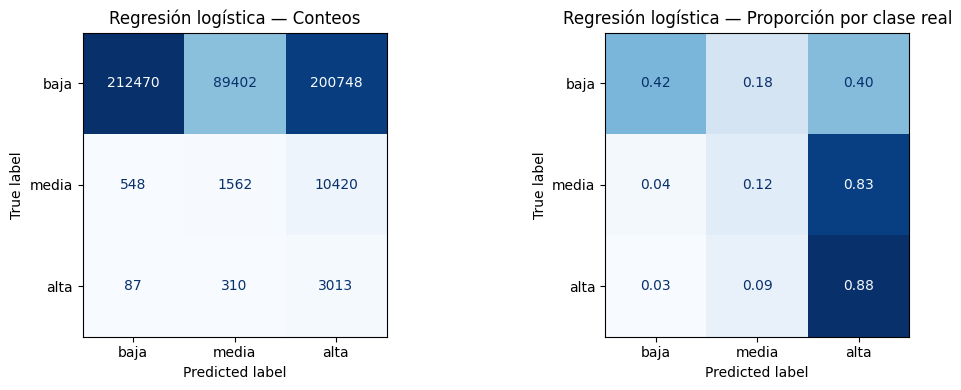


ÁRBOL DE DECISIÓN
              precision    recall  f1-score   support

        baja       0.98      0.65      0.78    502620
       media       0.04      0.26      0.07     12530
        alta       0.01      0.40      0.02      3410

    accuracy                           0.64    518560
   macro avg       0.35      0.44      0.29    518560
weighted avg       0.95      0.64      0.76    518560



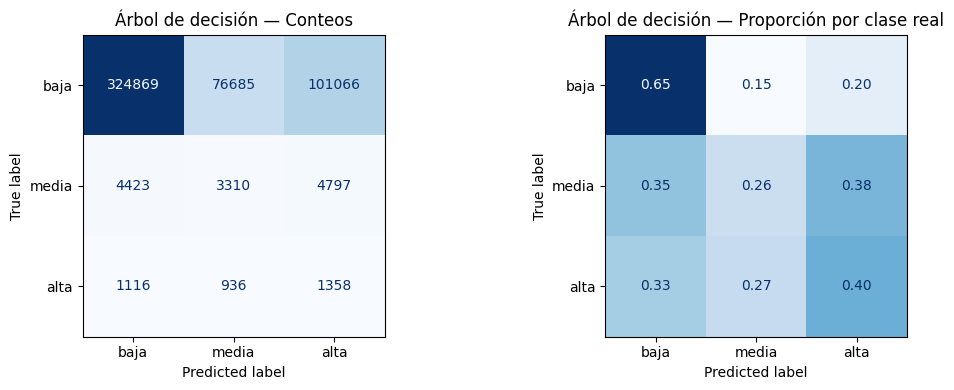


SVM (LINEARSVC)
              precision    recall  f1-score   support

        baja       0.98      0.90      0.94    502620
       media       0.17      0.00      0.00     12530
        alta       0.04      0.60      0.07      3410

    accuracy                           0.88    518560
   macro avg       0.40      0.50      0.34    518560
weighted avg       0.96      0.88      0.91    518560



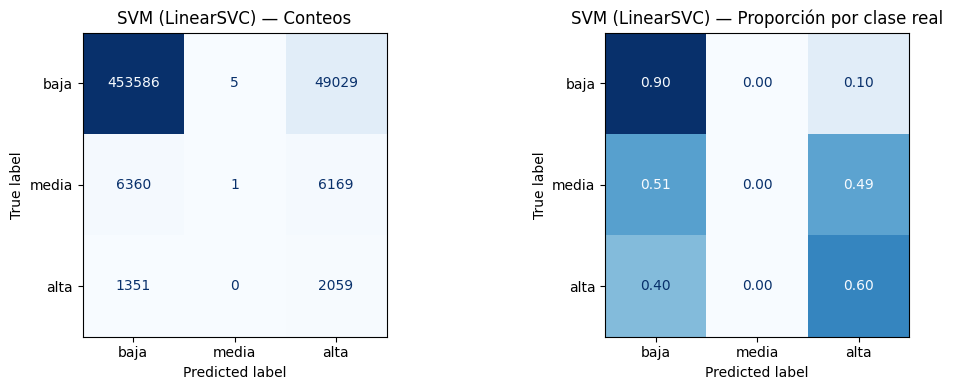

In [ ]:
def calcular_metricas(nombre, verdaderas, estimadas):
    return {
        'Modelo': nombre,
        'Accuracy': accuracy_score(verdaderas, estimadas),
        'Precision_macro': precision_score(verdaderas, estimadas, labels=CLASES, average='macro', zero_division=0),
        'Recall_macro': recall_score(verdaderas, estimadas, labels=CLASES, average='macro', zero_division=0),
        'F1_macro': f1_score(verdaderas, estimadas, labels=CLASES, average='macro', zero_division=0),
        'F1_weighted': f1_score(verdaderas, estimadas, labels=CLASES, average='weighted', zero_division=0)
    }

predicciones = {
    'Regresión logística': pred_logistica,
    'Árbol de decisión': pred_arbol,
    'SVM (LinearSVC)': pred_svm
}
resultados = {}
for nombre, estimadas in predicciones.items():
    resultados[nombre] = calcular_metricas(nombre, y_test, estimadas)
    print(f'\n{nombre.upper()}')
    print(classification_report(y_test, estimadas, labels=CLASES, zero_division=0))
    fig, ejes = plt.subplots(1, 2, figsize=(11,4))
    for eje, norma, titulo, formato in [
        (ejes[0], None, 'Conteos', 'd'),
        (ejes[1], 'true', 'Proporción por clase real', '.2f')
    ]:
        matriz = confusion_matrix(y_test, estimadas, labels=CLASES, normalize=norma)
        ConfusionMatrixDisplay(matriz, display_labels=CLASES).plot(
            ax=eje, cmap='Blues', colorbar=False, values_format=formato
        )
        eje.set_title(f'{nombre} — {titulo}')
    plt.tight_layout()
    plt.show()

### Importancia de características — árbol de decisión

La importancia se calcula a partir de las divisiones del árbol; no implica relaciones de causalidad.

,Variable,Importancia
169,numericas__anio,0.262002
170,numericas__mes,0.166509
171,numericas__dia_semana_num,0.124034
8,categoricas__codigo_provincia_09,0.040048
166,categoricas__franja_horaria_noche,0.026341
164,categoricas__franja_horaria_madrugada,0.020535
167,categoricas__franja_horaria_tarde,0.019955
11,categoricas__codigo_provincia_12,0.018100
165,categoricas__franja_horaria_manana,0.017505
7,categoricas__codigo_provincia_08,0.014000


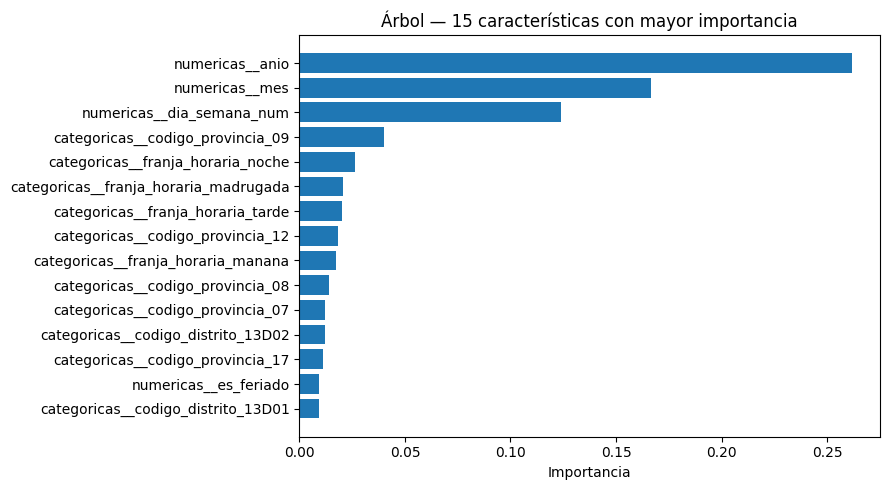

In [ ]:
importancias = pd.DataFrame({
    'Variable': preprocesador.get_feature_names_out(),
    'Importancia': modelo_arbol.feature_importances_
}).sort_values('Importancia', ascending=False).head(15)
display(importancias)
fig, ax = plt.subplots(figsize=(9,5))
ax.barh(importancias.Variable.iloc[::-1], importancias.Importancia.iloc[::-1])
ax.set(title='Árbol — 15 características con mayor importancia', xlabel='Importancia')
plt.tight_layout()
plt.show()

## 6. Comparación e interpretación

La referencia «siempre baja» permite detectar cuando un alto Accuracy oculta incapacidad de reconocer `media` y `alta`. **No se considera uno de los tres algoritmos exigidos.** La selección principal se realiza con F1 macro y se contrasta con el Recall por categoría.

In [ ]:
tabla_resultados = pd.DataFrame([resultados[nombre] for nombre in predicciones])
base = calcular_metricas('Referencia: siempre baja', y_test, np.full(len(y_test), 'baja'))
display(pd.concat([pd.DataFrame([base]), tabla_resultados], ignore_index=True).round(4))

recall_clases = {}
for nombre, estimadas in predicciones.items():
    matriz = confusion_matrix(y_test, estimadas, labels=CLASES)
    recall_clases[nombre] = np.divide(
        np.diag(matriz), matriz.sum(axis=1),
        out=np.zeros(len(CLASES),dtype=float), where=matriz.sum(axis=1) != 0
    )
tabla_recalls = pd.DataFrame(recall_clases, index=CLASES)
tabla_recalls.index.name = 'Recall por clase'
display(tabla_recalls.round(4))

ordenados = tabla_resultados.sort_values(['F1_macro','Recall_macro'], ascending=False)
mejor = ordenados.iloc[0]
print(f"Mayor F1 macro: {mejor['Modelo']} ({mejor['F1_macro']:.4f}).")
print(f"Referencia (siempre baja): {base['F1_macro']:.4f} F1 macro.")
if mejor['F1_macro'] <= base['F1_macro']:
    print('Advertencia: ningún modelo supera la referencia según F1 macro.')
else:
    print('La selección es exploratoria; revisar matrices y métricas por clase antes de concluir.')
clases_omitidas = [c for c in ['media', 'alta'] if tabla_recalls.loc[c, mejor['Modelo']] == 0]
if clases_omitidas:
    print('Advertencia: el modelo con mayor F1 macro no identifica:', ', '.join(clases_omitidas))
print('No se considera un modelo definitivo hasta evaluar el rendimiento de las tres clases.')

,Modelo,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_weighted
0,Referencia: siempre baja,0.9693,0.3231,0.3333,0.3281,0.9541
1,Regresión logística,0.4186,0.3427,0.4770,0.2172,0.5764
2,Árbol de decisión,0.6355,0.3456,0.4363,0.2918,0.7579
3,SVM (LinearSVC),0.8787,0.3953,0.5021,0.3364,0.9127


,Regresión logística,Árbol de decisión,SVM (LinearSVC)
Recall por clase,,,
baja,0.4227,0.6464,0.9024
media,0.1247,0.2642,0.0001
alta,0.8836,0.3982,0.6038


Mayor F1 macro: SVM (LinearSVC) (0.3364).
Referencia (siempre baja): 0.3281 F1 macro.
La selección es exploratoria; revisar matrices y métricas por clase antes de concluir.
No se considera un modelo definitivo hasta evaluar el rendimiento de las tres clases.


## 7. Conclusiones

Las siguientes conclusiones se generan a partir de la ejecución; no se asignan resultados antes de entrenar los modelos.

In [ ]:
texto = (
    f"**Modelos evaluados:** regresión logística, árbol de decisión y SVM. "
    f"Se utilizó una muestra de entrenamiento de {len(X_train):,} registros y "
    f"se evaluó sobre {len(X_test):,} registros de fechas posteriores.\n\n"
    f"**Mejor F1 macro:** {mejor['Modelo']} ({mejor['F1_macro']:.4f}), "
    f"frente a {base['F1_macro']:.4f} de la referencia que siempre predice baja. "
    f"Su Accuracy fue {mejor['Accuracy']:.4f}.\n\n"
    f"**Interpretación:** el ranking se basa en F1 macro por el desbalance de categorías. "
    f"El modelo líder alcanzó Recall de {tabla_recalls.loc['media', mejor['Modelo']]:.4f} en media "
    f"y de {tabla_recalls.loc['alta', mejor['Modelo']]:.4f} en alta. "
    f"Un liderazgo marginal frente a la referencia o un Recall nulo en alguna categoría "
    f"impiden considerarlo todavía una solución fiable.\n\n"
    f"**Limitaciones:** las categorías corresponden a conteos observados, no a una escala oficial de riesgo; "
    f"debe verificarse la cobertura del CSV y corroborar el desempeño con datos completos "
    f"y una validación temporal adicional antes de generalizar a todo Ecuador."
)
display(Markdown(texto))

**Modelos evaluados:** regresión logística, árbol de decisión y SVM. Se utilizó una muestra de entrenamiento de 300,000 registros y se evaluó sobre 518,560 registros de fechas posteriores.

**Mejor F1 macro:** SVM (LinearSVC) (0.3364), frente a 0.3281 de la referencia que siempre predice baja. Su Accuracy fue 0.8787.

**Interpretación:** el ranking se basa en F1 macro por el desbalance de categorías. El modelo líder alcanzó Recall de 0.0001 en media y de 0.6038 en alta. Un liderazgo marginal frente a la referencia o un Recall nulo en alguna categoría impiden considerarlo todavía una solución fiable.

**Limitaciones:** las categorías corresponden a conteos observados, no a una escala oficial de riesgo; debe verificarse la cobertura del CSV y corroborar el desempeño con datos completos y una validación temporal adicional antes de generalizar a todo Ecuador.

## 8. Exportación opcional

Activar `EXPORTAR = True` para guardar las métricas, matrices de confusión y predicciones en una subcarpeta de `Datos_Procesados`. El CSV original no se modifica.

In [ ]:
EXPORTAR = False
if EXPORTAR:
    salida = RUTA_DATOS.parent / 'Avance_II_Resultados'
    salida.mkdir(parents=True, exist_ok=True)
    tabla_resultados.to_csv(salida / 'metricas_3_modelos.csv', index=False)
    tabla_recalls.to_csv(salida / 'recall_por_clase.csv')
    pred_df = pd.DataFrame({
        'fecha': df.loc[mascara_test, 'fecha'].to_numpy(),
        'categoria_real': y_test.to_numpy()
    })
    nombres_archivo = {'Regresión logística':'logistica','Árbol de decisión':'arbol','SVM (LinearSVC)':'svm'}
    for nombre, estimadas in predicciones.items():
        corto = nombres_archivo[nombre]
        pred_df[f'pred_{corto}'] = estimadas
        matriz = confusion_matrix(y_test, estimadas, labels=CLASES)
        pd.DataFrame(matriz, index=CLASES, columns=CLASES).to_csv(salida / f'matriz_{corto}.csv')
    pred_df.to_csv(salida / 'predicciones_3_modelos.csv', index=False)
    print('Resultados guardados en', salida)
else:
    print('Exportación desactivada.')

Exportación desactivada.


## Seguimiento de sesiones de asesoría 1 a 1

### Avances presentados

Durante el desarrollo del Avance II se realizó la implementación de tres algoritmos de clasificación supervisada: Regresión Logística, Árbol de Decisión y Máquinas de Soporte Vectorial (SVM), utilizando el dataset procesado en el Avance I.

Se estableció como variable objetivo `categoria_incidencia`, que clasifica los registros en incidencia baja, media y alta. Se aplicaron técnicas de preparación de datos, codificación de variables categóricas y escalado de características cuando correspondía.

Posteriormente, se entrenaron los modelos y se evaluaron mediante matrices de confusión y métricas de Accuracy, Precision, Recall y F1-Score.

### Recomendaciones recibidas durante las asesorías

Durante las sesiones de seguimiento se recomendó considerar algoritmos más avanzados que permitan explorar relaciones complejas y mejorar la capacidad predictiva del proyecto.

Entre las alternativas sugeridas se encuentran:

- **Random Forest:** para combinar múltiples árboles de decisión y explorar relaciones no lineales entre las características.
- **Modelos de Boosting:** para evaluar métodos de ensamble que construyen modelos de manera secuencial buscando mejorar el desempeño.
- **LSTM (Long Short-Term Memory):** para explorar patrones temporales mediante redes neuronales recurrentes.
- **Transformers:** para considerar arquitecturas basadas en mecanismos de atención, especialmente si se desarrolla un enfoque de modelado temporal.

### Acciones realizadas y decisiones del equipo

Para el presente Avance II se decidió implementar inicialmente los tres algoritmos establecidos en el contenido de la asignatura: Regresión Logística, SVM y Árbol de Decisión.

Esta decisión permite construir una línea base de clasificación, comparar diferentes enfoques de aprendizaje supervisado e identificar las principales limitaciones del dataset y de los modelos iniciales.

Durante la evaluación se identificó un fuerte desbalance entre las categorías de incidencia, lo que afecta especialmente la clasificación de las clases minoritarias.

Las recomendaciones de incorporar Random Forest, Boosting, LSTM y Transformers se mantienen como posibles líneas de mejora para las siguientes etapas del proyecto. Su implementación requerirá experimentación adicional y una evaluación de su pertinencia según las características de los datos.

### Próximos pasos

En etapas posteriores se plantea evaluar modelos más avanzados, priorizando aquellos que puedan abordar las limitaciones identificadas en los clasificadores iniciales. Los resultados se compararán utilizando métricas que permitan considerar el desbalance de clases, especialmente el F1-Score macro y el desempeño individual de cada categoría.

## Conclusiones

1. Se implementaron y evaluaron tres algoritmos de clasificación supervisada: Regresión Logística, Árbol de Decisión y Máquinas de Soporte Vectorial (SVM), utilizando el dataset procesado en el Avance I. La preparación de los datos, la codificación de variables categóricas y la separación de los conjuntos de entrenamiento y prueba permitieron establecer una metodología común para comparar los modelos.

2. El modelo **SVM presentó el mejor desempeño general** entre los tres algoritmos evaluados, con una exactitud (Accuracy) de aproximadamente 87,87 % y un F1-Score macro de 0,3364. En comparación, el Árbol de Decisión obtuvo un F1 macro de 0,2918 y la Regresión Logística de 0,2172. Sin embargo, estos resultados no implican que el SVM tenga un desempeño satisfactorio en todas las categorías, ya que presenta dificultades importantes para identificar la incidencia media.

3. Se identificó que el **desbalance de clases constituye una de las principales limitaciones del proyecto**, debido al predominio de registros con incidencia baja. Esta distribución influye en el aprendizaje de los modelos y puede generar métricas globales elevadas que no reflejan adecuadamente el desempeño en las clases minoritarias. Por ello, el análisis de Precision, Recall, F1-Score y las matrices de confusión resultó fundamental para interpretar los resultados más allá del Accuracy.

4. La comparación evidenció diferencias en el comportamiento de los algoritmos. Mientras que SVM consiguió un mejor reconocimiento de la categoría baja, el Árbol de Decisión identificó una mayor proporción de registros de incidencia media y la Regresión Logística presentó un mayor Recall para la categoría alta. Esto demuestra que la selección de un modelo debe considerar no solo su desempeño general, sino también la capacidad de identificar las categorías relevantes para el problema.

5. Durante las sesiones de asesoría se recomendó considerar modelos más avanzados, como Random Forest, Boosting, LSTM y Transformers, con el propósito de explorar relaciones más complejas y posibles patrones temporales. Para este avance se priorizaron los tres algoritmos estudiados en clase, estableciendo una línea base que permitirá evaluar posteriormente si los modelos avanzados ofrecen mejoras reales en la clasificación.

6. Finalmente, se concluye que **los modelos desarrollados representan una primera aproximación al análisis predictivo de la incidencia de homicidios**, pero todavía presentan limitaciones para distinguir adecuadamente las tres categorías. Como trabajo futuro se propone evaluar algoritmos más avanzados, revisar estrategias para abordar el desbalance y comparar los resultados mediante métricas por clase, priorizando la capacidad de generalización y la identificación de las incidencias media y alta.